# Practical 9: End-to-End Data Pipelines: E-Commerce ETL with Historical and Newly Arriving Data

|  |  |
|---|---|
| **Name** | Aayushman Verma |
| **Roll No.** | 57 |
| **College** | B. K. Birla College, Kalyan |
| **Student ID** | 5176202 |

**Aim:** To build an end-to-end pipeline from a CSV file through Pandas cleaning and a SQL database to a report; to build an ETL pipeline for an e-commerce data set with customers, products, orders and payments; and to design a pipeline that processes historical data and newly arriving files without loading anything twice.

## Task 1: Pipeline 1 - CSV to Pandas to Cleaning to SQL Database to Report

Name: Ayushman Rajeev Verma
Rows: raw = 10, clean = 6  ->  4 rows removed
booking_id  show_date        movie  seats  revenue  weekday
        B1 2026-03-02    Inception      3    750.0   Monday
        B2 2026-03-02 Interstellar      2    600.0   Monday
        B3 2026-03-03    Inception      4   1000.0  Tuesday
        B6 2026-03-06         Dune      6   1680.0   Friday
        B7 2026-03-07    Inception      2    500.0 Saturday
        B9 2026-03-08 Interstellar      3    900.0   Sunday

REPORT - revenue by movie
       movie  bookings  seats_sold  revenue  avg_price
   Inception         3           9   2250.0      250.0
        Dune         1           6   1680.0      280.0
Interstellar         2           5   1500.0      300.0

REPORT - best selling weekday: Friday with Rs. 1680


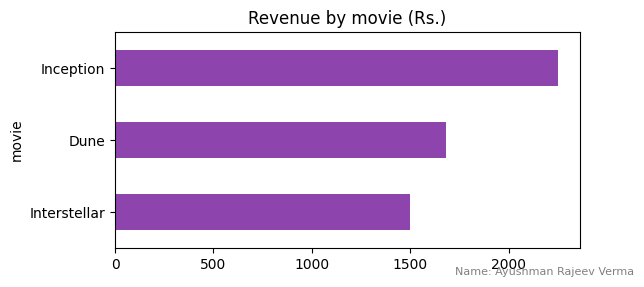

In [1]:
# Name: Ayushman Rajeev Verma
# PIPELINE 1 : movie-theatre bookings  CSV -> Pandas (method chaining) -> SQL database -> report
print("Name: Ayushman Rajeev Verma")
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

with open("bookings_raw.csv", "w") as f:
    f.write("booking_id,show_date,movie,seats,price_per_seat,screen\n")
    f.write("\n".join([
        "B1,2026-03-02,  inception ,3,250,Screen 1", "B2,2026-03-02,INTERSTELLAR,2,300,Screen 2",
        "B3,2026-03-03,Inception,4,250,Screen 1",    "B3,2026-03-03,Inception,4,250,Screen 1",
        "B4,2026-03-04,Dune,-2,280,Screen 3",        "B5,2026-03-05,Interstellar,5,,Screen 2",
        "B6,2026-03-06,dune,6,280,Screen 3",         "B7,2026-03-07,Inception,2,250,Screen 1",
        "B8,31-13-2026,Dune,2,280,Screen 3",         "B9,2026-03-08,Interstellar,3,300,Screen 2"]) + "\n")

# small, named cleaning steps that are chained with .pipe()
def tidy_text(d):    return d.assign(movie=d["movie"].str.strip().str.title(), screen=d["screen"].str.strip())
def parse_dates(d):  return d.assign(show_date=pd.to_datetime(d["show_date"], format="%Y-%m-%d", errors="coerce"))
def drop_invalid(d): return d.dropna(subset=["show_date", "price_per_seat"]).query("seats > 0")
def add_revenue(d):  return d.assign(revenue=d["seats"] * d["price_per_seat"], weekday=d["show_date"].dt.day_name())

raw = pd.read_csv("bookings_raw.csv")
clean = (raw.drop_duplicates().pipe(tidy_text).pipe(parse_dates).pipe(drop_invalid).pipe(add_revenue))
print(f"Rows: raw = {len(raw)}, clean = {len(clean)}  ->  {len(raw) - len(clean)} rows removed")
print(clean[["booking_id", "show_date", "movie", "seats", "revenue", "weekday"]].to_string(index=False))

con1 = sqlite3.connect("theatre.db")
clean.assign(show_date=clean["show_date"].dt.strftime("%Y-%m-%d")).to_sql("bookings", con1, if_exists="replace", index=False)

report = pd.read_sql("""SELECT movie, COUNT(*) AS bookings, SUM(seats) AS seats_sold, SUM(revenue) AS revenue,
                               ROUND(AVG(price_per_seat), 1) AS avg_price
                        FROM bookings GROUP BY movie ORDER BY revenue DESC""", con1)
print("\nREPORT - revenue by movie")
print(report.to_string(index=False))
by_day = pd.read_sql("SELECT weekday, SUM(revenue) AS revenue FROM bookings GROUP BY weekday ORDER BY revenue DESC", con1)
print("\nREPORT - best selling weekday:", by_day.iloc[0, 0], "with Rs.", int(by_day.iloc[0, 1]))
report.to_csv("theatre_report.csv", index=False)

ax = report.plot(kind="barh", x="movie", y="revenue", color="#8e44ad", legend=False, figsize=(6, 2.8))
ax.set_title("Revenue by movie (Rs.)"); ax.invert_yaxis()
plt.gcf().text(0.99, 0.005, "Name: Ayushman Rajeev Verma", ha="right", va="bottom", fontsize=8, color="gray")
plt.savefig("p9_theatre.png", dpi=110, bbox_inches="tight")
plt.show()

## Task 2: Pipeline 2 - Create the E-Commerce Source Data (Master Data and Inbox Files)

Customers and products are master data. Orders (with their payment details) arrive as files in an inbox folder: one historical monthly file and daily files that come later.

In [2]:
# PIPELINE 2 : GadgetHub e-commerce ETL  (customers, products, orders, payments)
print("Name: Ayushman Rajeev Verma")
import os, glob

os.makedirs("inbox", exist_ok=True)
customers_df = pd.DataFrame({
    "customer_id": ["C01", "C02", "C03", "C04", "C05"],
    "name": ["aman gupta", "Bhavna Rao", "chirag shah", "Divya Menon", "Esha Kapoor"],
    "email": ["aman@mail.com", "bhavna@mail.com", "CHIRAG@MAIL.COM", "divya@mail", "esha@mail.com"],
    "city": ["Mumbai", "Pune", "Nashik", "Delhi", "Pune"]})
products_df = pd.DataFrame({
    "sku": ["G1", "G2", "G3", "G4", "G5"],
    "product_name": ["Wireless Earbuds", "Smart Watch", "Power Bank 20000mAh", "Bluetooth Speaker", "USB-C Hub"],
    "category": ["Audio", "Wearables", "Accessories", "Audio", "Accessories"],
    "price": [2499, 6999, 1799, 3299, 1299]})

BATCH_HEADER = "order_id,customer_id,sku,qty,order_date,status,pay_amount,pay_mode,pay_status\n"
def write_batch(name, rows):
    with open(f"inbox/{name}", "w") as f:
        f.write(BATCH_HEADER + "\n".join(rows) + "\n")

write_batch("orders_2026-01.csv", [                      # HISTORICAL data (a whole month)
    "5001,C01,G1,1,2026-01-12,delivered,2499,UPI,PAID", "5002,C02,G2,1,2026-01-15,delivered,6999,CARD,PAID",
    "5003,C03,G3,2,2026-01-18,shipped,3598,UPI,PAID",   "5004,C05,G4,1,2026-01-22,placed,0,COD,PENDING",
    "5005,C09,G1,1,2026-01-25,delivered,2499,UPI,PAID", "5006,C04,G5,0,2026-01-26,placed,0,UPI,PENDING",
    "5007,C02,G9,1,2026-01-28,delivered,999,CARD,PAID", "5008,C01,G5,3,2026-01-30,delivered,3897,CARD,PAID"])
write_batch("orders_2026-02-01.csv", [                   # daily files that arrive later
    "5004,C05,G4,1,2026-01-22,shipped,3299,UPI,PAID",    # status update of a historical order
    "5009,C03,G2,1,2026-02-01,placed,6999,CARD,PAID", "5010,C04,G1,2,2026-02-01,delivered,4998,UPI,PAID"])
write_batch("orders_2026-02-02.csv", [
    "5011,C01,G3,1,2026-02-02,placed,1799,UPI,PAID", "5012,C05,G2,1,2026-02-02,delivered,6000,CARD,PAID"])
print("Inbox files:", sorted(os.listdir("inbox")))

Name: Ayushman Rajeev Verma
Inbox files: ['orders_2026-01.csv', 'orders_2026-02-01.csv', 'orders_2026-02-02.csv']


## Task 3: ETL Class - Clean, Validate and Load Each File (Historical Load)

The class cleans each file, rejects invalid orders with a reason, upserts orders and payments, and records every processed file in the pipeline_runs table.

In [3]:
print("Name: Ayushman Rajeev Verma")
class GadgetHubETL:
    """Extract -> clean -> load, one inbox file at a time. Every processed file is logged, so a file is never loaded twice."""
    def __init__(self, db_path):
        self.con = sqlite3.connect(db_path)
        self.con.executescript("""
        PRAGMA foreign_keys = ON;
        DROP TABLE IF EXISTS payments; DROP TABLE IF EXISTS orders; DROP TABLE IF EXISTS rejected_orders;
        DROP TABLE IF EXISTS pipeline_runs; DROP TABLE IF EXISTS products; DROP TABLE IF EXISTS customers;
        CREATE TABLE customers (customer_id TEXT PRIMARY KEY, name TEXT, email TEXT, city TEXT);
        CREATE TABLE products  (sku TEXT PRIMARY KEY, product_name TEXT, category TEXT, price REAL);
        CREATE TABLE orders (order_id INTEGER PRIMARY KEY, customer_id TEXT NOT NULL REFERENCES customers, sku TEXT NOT NULL REFERENCES products,
                             qty INTEGER CHECK (qty > 0), order_date TEXT, status TEXT);
        CREATE TABLE payments (order_id INTEGER PRIMARY KEY REFERENCES orders, amount REAL CHECK (amount > 0), mode TEXT, status TEXT);
        CREATE TABLE rejected_orders (file_name TEXT, order_id INTEGER, reason TEXT);
        CREATE TABLE pipeline_runs (file_name TEXT PRIMARY KEY, rows_in INTEGER, orders_new INTEGER, orders_updated INTEGER, payments_saved INTEGER, rejected INTEGER);
        """)

    def load_masters(self, customers, products):
        c = customers.assign(name=customers["name"].str.strip().str.title(), email=customers["email"].str.lower())
        c.loc[~c["email"].str.match(r"^[\w.]+@\w+\.[a-z]{2,}$"), "email"] = None          # invalid e-mail -> NULL
        c.to_sql("customers", self.con, if_exists="append", index=False)
        products.to_sql("products", self.con, if_exists="append", index=False)

    def process_file(self, path):
        name = os.path.basename(path)
        df = pd.read_csv(path)
        df["status"] = df["status"].str.upper()
        customers = set(pd.read_sql("SELECT customer_id FROM customers", self.con)["customer_id"])
        skus = set(pd.read_sql("SELECT sku FROM products", self.con)["sku"])
        reason = pd.Series("", index=df.index)
        reason[df["qty"] <= 0] = "quantity must be positive"
        reason[~df["sku"].isin(skus)] = "unknown product"
        reason[~df["customer_id"].isin(customers)] = "unknown customer"
        bad, good = df[reason != ""], df[reason == ""]
        for oid, why in zip(bad["order_id"], reason[reason != ""]):
            self.con.execute("INSERT INTO rejected_orders VALUES (?,?,?)", (name, int(oid), why))

        existing = set(pd.read_sql("SELECT order_id FROM orders", self.con)["order_id"])
        new = int((~good["order_id"].isin(existing)).sum())
        self.con.executemany("""INSERT INTO orders VALUES (?,?,?,?,?,?)
                                ON CONFLICT(order_id) DO UPDATE SET status = excluded.status""",
                             good[["order_id", "customer_id", "sku", "qty", "order_date", "status"]].astype(object).values.tolist())
        paid = good[good["pay_amount"] > 0]
        self.con.executemany("""INSERT INTO payments VALUES (?,?,?,?)
                                ON CONFLICT(order_id) DO UPDATE SET amount = excluded.amount, mode = excluded.mode, status = excluded.status""",
                             paid[["order_id", "pay_amount", "pay_mode", "pay_status"]].astype(object).values.tolist())
        self.con.execute("INSERT INTO pipeline_runs VALUES (?,?,?,?,?,?)", (name, len(df), new, len(good) - new, len(paid), len(bad)))
        self.con.commit()
        print(f"  {name:<22} rows={len(df)}  new={new}  updated={len(good) - new}  payments={len(paid)}  rejected={len(bad)}")

    def run(self, inbox):
        done = {r[0] for r in self.con.execute("SELECT file_name FROM pipeline_runs")}
        todo = [p for p in sorted(glob.glob(f"{inbox}/orders_*.csv")) if os.path.basename(p) not in done]
        print(f"Run: {len(todo)} new file(s) to process, {len(done)} already processed")
        for p in todo:
            self.process_file(p)

etl = GadgetHubETL("gadgethub.db")
etl.load_masters(customers_df, products_df)
print("RUN 1 - historical file + the first daily files")
etl.run("inbox")
print("\nRejected orders:")
print(pd.read_sql("SELECT * FROM rejected_orders", etl.con).to_string(index=False))

Name: Ayushman Rajeev Verma
RUN 1 - historical file + the first daily files
Run: 3 new file(s) to process, 0 already processed
  orders_2026-01.csv     rows=8  new=5  updated=0  payments=4  rejected=3
  orders_2026-02-01.csv  rows=3  new=2  updated=1  payments=3  rejected=0
  orders_2026-02-02.csv  rows=2  new=2  updated=0  payments=2  rejected=0

Rejected orders:
         file_name  order_id                    reason
orders_2026-01.csv      5005          unknown customer
orders_2026-01.csv      5006 quantity must be positive
orders_2026-01.csv      5007           unknown product


## Task 4: Newly Arriving Data - Process Only New Files

In [4]:
# NEW DATA ARRIVES: one more daily file, containing a new order and a status update of an old order
print("Name: Ayushman Rajeev Verma")
write_batch("orders_2026-02-03.csv", [
    "5013,C02,G4,2,2026-02-03,placed,6598,CARD,PAID",
    "5003,C03,G3,2,2026-01-18,delivered,3598,UPI,PAID"])

print("Status of order 5003 BEFORE:", etl.con.execute("SELECT status FROM orders WHERE order_id = 5003").fetchone()[0])
print("RUN 2 - only the new file is processed")
etl.run("inbox")
print("Status of order 5003 AFTER :", etl.con.execute("SELECT status FROM orders WHERE order_id = 5003").fetchone()[0])
print("\nRUN 3 - nothing new in the inbox")
etl.run("inbox")

print("\nPipeline log:")
print(pd.read_sql("SELECT * FROM pipeline_runs", etl.con).to_string(index=False))

Name: Ayushman Rajeev Verma
Status of order 5003 BEFORE: SHIPPED
RUN 2 - only the new file is processed
Run: 1 new file(s) to process, 3 already processed
  orders_2026-02-03.csv  rows=2  new=1  updated=1  payments=2  rejected=0
Status of order 5003 AFTER : DELIVERED

RUN 3 - nothing new in the inbox
Run: 0 new file(s) to process, 4 already processed

Pipeline log:
            file_name  rows_in  orders_new  orders_updated  payments_saved  rejected
   orders_2026-01.csv        8           5               0               4         3
orders_2026-02-01.csv        3           2               1               3         0
orders_2026-02-02.csv        2           2               0               2         0
orders_2026-02-03.csv        2           1               1               2         0


## Task 5: Business Report

Name: Ayushman Rajeev Verma
1. REVENUE BY CATEGORY (cancelled orders excluded)
   category  orders  units  revenue
  Wearables       3      3  20997.0
      Audio       4      6  17394.0
Accessories       3      6   9294.0

2. DAILY REVENUE WITH RUNNING TOTAL (window function)
order_date  revenue  running_total
2026-01-12   2499.0         2499.0
2026-01-15   6999.0         9498.0
2026-01-18   3598.0        13096.0
2026-01-22   3299.0        16395.0
2026-01-30   3897.0        20292.0
2026-02-01  11997.0        32289.0
2026-02-02   8798.0        41087.0
2026-02-03   6598.0        47685.0

3. PAYMENT CHECK (order value vs amount paid)
 order_id    customer  order_value   paid check_result
     5001  Aman Gupta       2499.0 2499.0      MATCHED
     5002  Bhavna Rao       6999.0 6999.0      MATCHED
     5003 Chirag Shah       3598.0 3598.0      MATCHED
     5004 Esha Kapoor       3299.0 3299.0      MATCHED
     5008  Aman Gupta       3897.0 3897.0      MATCHED
     5009 Chirag Shah       69

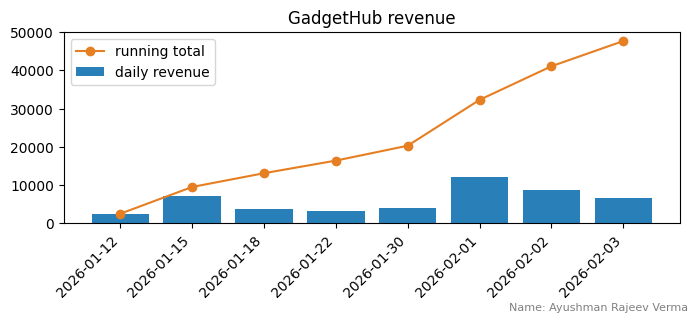

In [5]:
print("Name: Ayushman Rajeev Verma")
con = etl.con
print("1. REVENUE BY CATEGORY (cancelled orders excluded)")
print(pd.read_sql("""SELECT p.category, COUNT(*) AS orders, SUM(o.qty) AS units, SUM(o.qty * p.price) AS revenue
                     FROM orders o JOIN products p USING (sku) WHERE o.status <> 'CANCELLED'
                     GROUP BY p.category ORDER BY revenue DESC""", con).to_string(index=False))

print("\n2. DAILY REVENUE WITH RUNNING TOTAL (window function)")
daily = pd.read_sql("""SELECT order_date, SUM(o.qty * p.price) AS revenue,
                              SUM(SUM(o.qty * p.price)) OVER (ORDER BY order_date) AS running_total
                       FROM orders o JOIN products p USING (sku) GROUP BY order_date ORDER BY order_date""", con)
print(daily.to_string(index=False))

print("\n3. PAYMENT CHECK (order value vs amount paid)")
print(pd.read_sql("""SELECT o.order_id, c.name AS customer, o.qty * p.price AS order_value, COALESCE(y.amount, 0) AS paid,
                            CASE WHEN y.amount IS NULL THEN 'NO PAYMENT'
                                 WHEN y.amount = o.qty * p.price THEN 'MATCHED' ELSE 'MISMATCH' END AS check_result
                     FROM orders o JOIN customers c USING (customer_id) JOIN products p USING (sku)
                     LEFT JOIN payments y USING (order_id) ORDER BY o.order_id""", con).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(daily["order_date"], daily["revenue"], color="#2980b9", label="daily revenue")
ax.plot(daily["order_date"], daily["running_total"], color="#e67e22", marker="o", label="running total")
ax.set_title("GadgetHub revenue"); ax.legend(); plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.gcf().text(0.99, 0.005, "Name: Ayushman Rajeev Verma", ha="right", va="bottom", fontsize=8, color="gray")
plt.savefig("p9_gadgethub.png", dpi=110, bbox_inches="tight")
plt.show()

**Conclusion:** Pipeline 1 turned a raw CSV file into a clean table and a revenue report. Pipeline 2 loaded historical and daily e-commerce files with a reusable ETL class: invalid orders were rejected with reasons, existing orders were updated through upserts, new orders were inserted, and the run log made sure a file was never processed twice, so the pipeline can be run again at any time.